# Path A, P6 — target 9: Agreement at reversal (Oct 26, 2026)

Runs: `load_runs("behavior", roles={"train", "val"}, keep_bot=False, keep_incomplete=False)` (the runs of target 8 (b)). Reversals: `detect_events` with m = 2 on every human player. CC runs first go through `lab_log` (tick 0.1 s); lab data (EL, CL) are used as logged. Check: CC on its raw rows.

- **Agreement A_i:** `slider_logs.agreement(A_log, s) / 100` (via `hazard.agreement`), in [0, 1]. It recomputes the logged Agreement column from the slider positions (within 0.005 percentage points of the log on these runs), so it also works on lab-clocked CC rows.
- **f_rev:** A_i of the reverser at the last row before the reversal's first step (`row_before`).
- **f_time:** `hazard.at_risk_samples` (b = 0.25 s): A_i sampled by forward hold at bin starts, from the player's first move (first row where k = round(10 s) changes) to `fraught.round_end` of the rows used (for lab-clocked CC within 0.005 s of the raw round end).
- **h(A):** reversals in an A bin / at-risk minutes in that bin (samples x b / 60); bins of width 0.1, left-closed, the last includes 1.0. Bins with < 0.5 at-risk minutes are flagged.
- **95% CIs:** group bootstrap (log files, 10,000 resamples, seed 573). A resample with no at-risk time in a bin counts as rate +inf.

Function: `targets.agreement_at_reversal_table` (`src/slider/targets.py`). Saved: `results/tables/target9_agreement_at_reversal.csv`, `results/tables/target9_hazard.csv`, `results/figures/target9_agreement_at_reversal.png`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from slider import config
from slider import slider_logs as sl
from slider import targets
from slider.labclock import CELLS

pd.set_option("display.max_columns", 30)

runs, table = sl.load_runs("behavior", roles={"train", "val"}, keep_bot=False, keep_incomplete=False)
summary, h = targets.agreement_at_reversal_table(runs)                          # about 1.5 min
summary_raw, h_raw = targets.agreement_at_reversal_table(runs, lab_clock_cc=False)

In [2]:
def wide(s):
    """One row per cell and measure, one column per stat: "value [lo, hi]"."""
    s = s.assign(cell=[f"{v:.3f} [{lo:.3f}, {hi:.3f}]" for v, lo, hi in zip(s["value"], s["ci_lo"], s["ci_hi"])])
    w = s.pivot_table(index=["topology", "dataset", "measure", "groups", "runs", "n"], columns="stat",
                      values="cell", aggfunc="first", sort=False)
    return w[targets.A_STATS]


def wide_h(h):
    """One row per A bin, one column per cell: "rate [lo, hi]"."""
    h = h.assign(bin=[f"[{lo:.1f}, {hi:.1f}{']' if hi == 1 else ')'}" for lo, hi in zip(h["A_lo"], h["A_hi"])],
                 cell=[f"{v:.2f} [{lo:.2f}, {hi:.2f}]" for v, lo, hi in zip(h["rate"], h["ci_lo"], h["ci_hi"])])
    return h.pivot_table(index="bin", columns=["topology", "dataset"], values="cell", aggfunc="first", sort=False)

## Per cell: f_rev and f_time (CC on the lab clock)

In [3]:
wide(summary)

stat                                                        median  \
topology  dataset measure groups runs n                              
Hierarchy EL      f_rev   17     51   1610    0.375 [0.333, 0.500]   
                  f_time  17     51   101391  0.850 [0.750, 0.950]   
          CL      f_rev   18     53   1229    0.333 [0.302, 0.367]   
                  f_time  18     53   92764   0.800 [0.720, 0.900]   
          CC      f_rev   16     40   940     0.333 [0.325, 0.350]   
                  f_time  16     40   57921   0.950 [0.867, 0.967]   
Full      CL      f_rev   18     54   2864    0.296 [0.257, 0.343]   
                  f_time  18     54   170521  0.500 [0.457, 0.557]   
          CC      f_rev   16     36   1245    0.314 [0.271, 0.372]   
                  f_time  16     36   53699   0.514 [0.429, 0.571]   
Star      CC      f_rev   17     39   622     0.286 [0.200, 0.350]   
                  f_time  17     39   36364   0.714 [0.600, 0.800]   

stat                                                            q1  \
topology  dataset measure groups runs n                              
Hierarchy EL      f_rev   17     51   1610    0.150 [0.081, 0.200]   
                  f_time  17     51   101391  0.400 [0.350, 0.475]   
          CL      f_rev   18     53   1229    0.100 [0.068, 0.150]   
                  f_time  18     53   92764   0.420 [0.350, 0.490]   
          CC      f_rev   16     40   940     0.050 [0.000, 0.125]   
                  f_time  16     40   57921   0.450 [0.375, 0.500]   
Full      CL      f_rev   18     54   2864    0.129 [0.114, 0.143]   
                  f_time  18     54   170521  0.257 [0.229, 0.294]   
          CC      f_rev   16     36   1245    0.143 [0.129, 0.157]   
                  f_time  16     36   53699   0.271 [0.229, 0.314]   
Star      CC      f_rev   17     39   622     0.050 [0.000, 0.050]   
                  f_time  17     39   36364   0.350 [0.300, 0.400]   

stat                                                            q3  \
topology  dataset measure groups runs n                              
Hierarchy EL      f_rev   17     51   1610    0.633 [0.500, 0.750]   
                  f_time  17     51   101391  1.000 [1.000, 1.000]   
          CL      f_rev   18     53   1229    0.567 [0.500, 0.625]   
                  f_time  18     53   92764   1.000 [1.000, 1.000]   
          CC      f_rev   16     40   940     0.650 [0.500, 0.850]   
                  f_time  16     40   57921   1.000 [1.000, 1.000]   
Full      CL      f_rev   18     54   2864    0.536 [0.457, 0.606]   
                  f_time  18     54   170521  0.714 [0.700, 0.786]   
          CC      f_rev   16     36   1245    0.529 [0.429, 0.586]   
                  f_time  16     36   53699   0.714 [0.700, 0.714]   
Star      CC      f_rev   17     39   622     0.500 [0.500, 0.500]   
                  f_time  17     39   36364   1.000 [1.000, 1.000]   

stat                                                     pct_A_gt_0.5  
topology  dataset measure groups runs n                                
Hierarchy EL      f_rev   17     51   1610    32.795 [23.321, 41.296]  
                  f_time  17     51   101391  66.251 [62.292, 69.212]  
          CL      f_rev   18     53   1229    29.048 [24.508, 32.569]  
                  f_time  18     53   92764   66.887 [61.847, 71.275]  
          CC      f_rev   16     40   940     27.553 [19.136, 33.302]  
                  f_time  16     40   57921   66.187 [63.264, 69.336]  
Full      CL      f_rev   18     54   2864    27.130 [21.363, 33.582]  
                  f_time  18     54   170521  49.265 [44.737, 54.868]  
          CC      f_rev   16     36   1245    27.390 [20.458, 34.142]  
                  f_time  16     36   53699   51.005 [43.642, 57.749]  
Star      CC      f_rev   17     39   622     20.418 [14.806, 24.964]  
                  f_time  17     39   36364   58.814 [53.988, 64.158]

## Check: CC on its raw rows (lab cells unchanged)

In [4]:
lab = summary["dataset"] != "CC"
print("lab cells identical in both tables:", summary[lab].equals(summary_raw[lab]))
wide(summary_raw[~lab])

lab cells identical in both tables: True


stat                                                       median  \
topology  dataset measure groups runs n                             
Hierarchy CC      f_rev   16     40   942    0.333 [0.325, 0.350]   
                  f_time  16     40   57988  0.950 [0.867, 0.967]   
Full      CC      f_rev   16     36   1247   0.314 [0.271, 0.371]   
                  f_time  16     36   53761  0.514 [0.429, 0.571]   
Star      CC      f_rev   17     39   622    0.300 [0.200, 0.350]   
                  f_time  17     39   36416  0.714 [0.600, 0.800]   

stat                                                           q1  \
topology  dataset measure groups runs n                             
Hierarchy CC      f_rev   16     40   942    0.050 [0.000, 0.100]   
                  f_time  16     40   57988  0.450 [0.375, 0.500]   
Full      CC      f_rev   16     36   1247   0.143 [0.129, 0.157]   
                  f_time  16     36   53761  0.271 [0.229, 0.314]   
Star      CC      f_rev   17     39   622    0.050 [0.000, 0.050]   
                  f_time  17     39   36416  0.350 [0.300, 0.400]   

stat                                                           q3  \
topology  dataset measure groups runs n                             
Hierarchy CC      f_rev   16     40   942    0.650 [0.500, 0.850]   
                  f_time  16     40   57988  1.000 [1.000, 1.000]   
Full      CC      f_rev   16     36   1247   0.529 [0.443, 0.586]   
                  f_time  16     36   53761  0.714 [0.700, 0.714]   
Star      CC      f_rev   17     39   622    0.500 [0.500, 0.514]   
                  f_time  17     39   36416  1.000 [1.000, 1.000]   

stat                                                    pct_A_gt_0.5  
topology  dataset measure groups runs n                               
Hierarchy CC      f_rev   16     40   942    27.707 [18.871, 33.551]  
                  f_time  16     40   57988  66.179 [63.266, 69.320]  
Full      CC      f_rev   16     36   1247   27.426 [20.532, 34.213]  
                  f_time  16     36   53761  51.011 [43.655, 57.762]  
Star      CC      f_rev   17     39   622    20.740 [14.938, 25.339]  
                  f_time  17     39   36416  58.776 [53.937, 64.124]

## h(A): reversals per at-risk minute (CC on the lab clock)

In [5]:
wide_h(h)

topology               Hierarchy                                            \
dataset                       EL                   CL                   CC   
bin                                                                          
[0.0, 0.1)  12.04 [10.35, 13.91]  11.20 [9.36, 13.23]  13.21 [9.78, 17.06]   
[0.1, 0.2)     7.43 [5.71, 9.71]    5.71 [4.15, 7.19]    7.77 [5.74, 9.36]   
[0.2, 0.3)     6.48 [5.19, 7.75]    5.00 [3.23, 7.25]    7.39 [5.71, 9.25]   
[0.3, 0.4)     6.86 [5.64, 8.07]    7.04 [4.78, 9.55]    7.26 [5.05, 9.60]   
[0.4, 0.5)     5.41 [4.35, 6.58]    5.11 [3.91, 6.45]    6.56 [4.69, 8.75]   
[0.5, 0.6)     6.65 [4.86, 8.82]    4.89 [3.37, 6.56]    4.44 [3.50, 5.75]   
[0.6, 0.7)     4.81 [2.82, 6.72]    3.19 [1.82, 4.88]    3.34 [2.02, 4.80]   
[0.7, 0.8)     4.58 [2.74, 6.65]    2.64 [1.91, 3.52]    2.49 [1.17, 3.90]   
[0.8, 0.9)     4.27 [2.06, 6.55]    2.48 [1.44, 3.74]    3.46 [1.76, 4.74]   
[0.9, 1.0]     0.78 [0.35, 1.48]    0.58 [0.35, 0.84]    1.33 [0.61, 2.33]   

topology                  Full                                      Star  
dataset                     CL                   CC                   CC  
bin                                                                       
[0.0, 0.1)  8.96 [7.12, 10.92]  10.79 [9.43, 12.16]  11.47 [9.77, 13.62]  
[0.1, 0.2)   6.72 [5.49, 7.83]   9.77 [8.21, 11.58]    7.30 [5.29, 9.47]  
[0.2, 0.3)   5.72 [4.67, 6.89]    7.95 [6.85, 9.08]    6.56 [5.29, 7.84]  
[0.3, 0.4)   4.37 [3.50, 5.49]    6.86 [5.73, 8.30]    4.85 [3.12, 6.60]  
[0.4, 0.5)   3.98 [3.22, 4.80]    6.77 [5.93, 7.87]    6.24 [4.48, 8.52]  
[0.5, 0.6)   3.03 [2.16, 4.12]    4.48 [3.45, 5.53]    6.24 [4.91, 7.80]  
[0.6, 0.7)   2.94 [2.28, 3.66]    4.10 [2.79, 5.19]    3.86 [2.38, 5.43]  
[0.7, 0.8)   2.00 [1.39, 2.87]    2.54 [1.96, 3.20]    2.95 [1.63, 4.33]  
[0.8, 0.9)   2.02 [1.13, 2.85]    1.40 [0.66, 1.92]    2.43 [1.17, 3.66]  
[0.9, 1.0]   1.16 [0.59, 2.29]    1.28 [0.40, 2.48]    0.67 [0.33, 1.03]

In [6]:
print("at-risk minutes per bin")
h.pivot_table(index="A_lo", columns=["topology", "dataset"], values="at_risk_min", sort=False).round(2)

at-risk minutes per bin


topology Hierarchy                   Full          Star
dataset         EL      CL      CC     CL     CC     CC
A_lo                                                   
0.0          25.59   25.27   20.07  61.48  18.25  18.04
0.1          18.85   20.32    7.85  69.83  22.52   7.81
0.2          21.13   23.02    8.66  72.70  22.02   7.32
0.3          33.55   22.58   19.14  73.94  19.10   7.01
0.4          22.19   19.75    9.60  75.62  25.12   8.66
0.5          35.20   32.74   22.28  70.57  24.77  17.80
0.6          20.60   23.81    7.79  70.70  25.88   5.70
0.7          20.95   25.38   10.85  93.21  39.00   9.50
0.8          20.40   20.98    7.80  62.34  10.73   8.22
0.9         204.01  172.66  127.30  60.11  16.36  61.45

In [7]:
print("flagged bins (< 0.5 at-risk minutes), lab clock:", int(h["sparse"].sum()), "  raw CC:", int(h_raw["sparse"].sum()))
pd.concat([h[h["sparse"]].assign(set="lab clock"), h_raw[h_raw["sparse"]].assign(set="raw CC")])

flagged bins (< 0.5 at-risk minutes), lab clock: 0   raw CC: 0


,topology,dataset,A_lo,A_hi,reversals,at_risk_min,rate,ci_lo,ci_hi,sparse,set


## Check: h(A) with CC on its raw rows

In [8]:
lab = h["dataset"] != "CC"
print("lab cells identical in both tables:", h[lab].equals(h_raw[lab]))
wide_h(h_raw[~lab])

lab cells identical in both tables: True


topology,Hierarchy,Full,Star
dataset,CC,CC,CC
bin,,,
"[0.0, 0.1)","13.17 [9.91, 16.89]","11.31 [9.88, 12.81]","11.42 [9.69, 13.59]"
"[0.1, 0.2)","7.88 [6.09, 9.58]","9.33 [7.85, 10.90]","7.16 [4.98, 9.61]"
"[0.2, 0.3)","7.37 [5.68, 9.29]","8.10 [6.96, 9.19]","6.28 [4.99, 7.69]"
"[0.3, 0.4)","7.36 [5.19, 9.74]","6.63 [5.58, 8.00]","5.44 [3.57, 7.34]"
"[0.4, 0.5)","6.10 [4.35, 7.76]","6.88 [5.97, 8.07]","6.19 [4.43, 8.46]"
"[0.5, 0.6)","4.68 [3.72, 5.94]","4.34 [3.51, 5.17]","6.13 [4.84, 7.61]"
"[0.6, 0.7)","3.05 [1.79, 4.37]","4.08 [2.73, 5.27]","3.88 [2.23, 5.73]"
"[0.7, 0.8)","2.60 [1.36, 3.98]","2.69 [2.01, 3.56]","3.03 [1.69, 4.35]"


## Figure

Top of each panel: h(A) with its 95% CI band (lab clock for CC). Underneath: the share of reversals (f_rev) and of at-risk time (f_time) in each A bin. Hollow points: bins with < 0.5 at-risk minutes (none here).

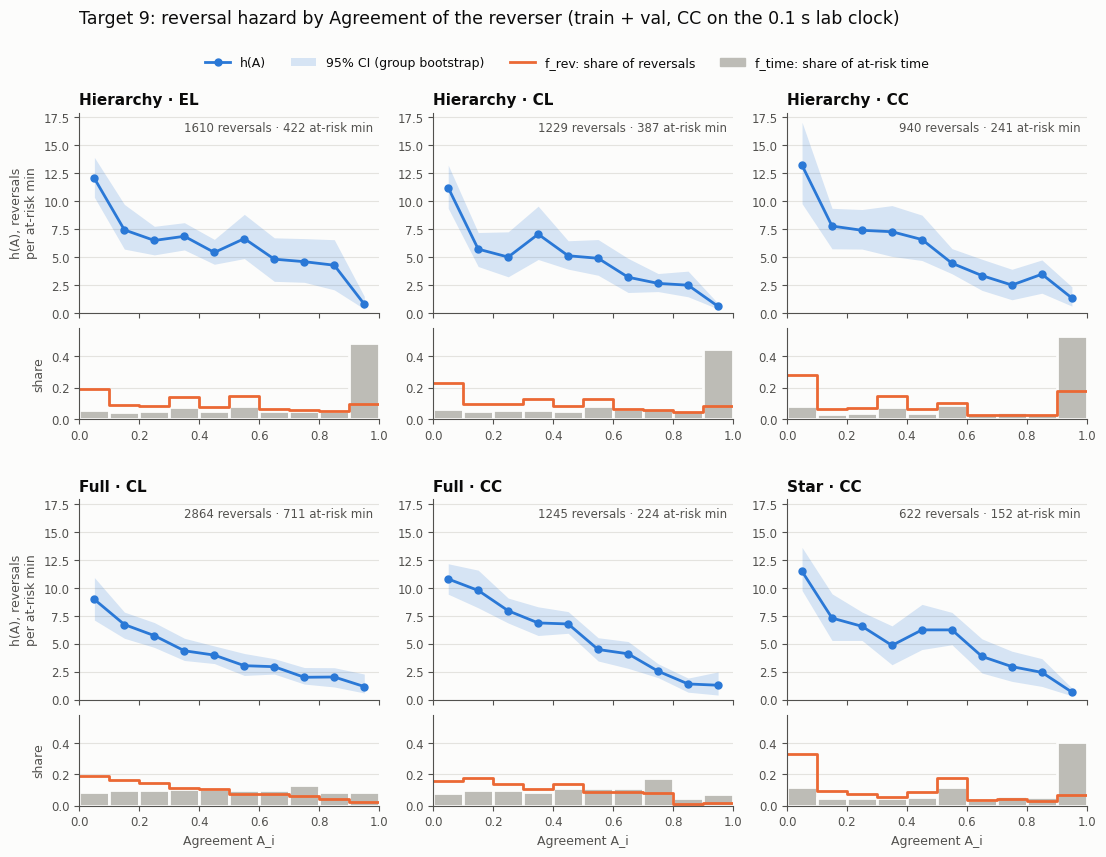

In [9]:
SURFACE, INK, INK_2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#bdbcb6"
mid = np.arange(10) / 10 + 0.05

fig = plt.figure(figsize=(13, 9), facecolor=SURFACE)
grid = fig.add_gridspec(5, 3, height_ratios=[2.2, 1, 0.55, 2.2, 1], hspace=0.12, wspace=0.18)
top_max = h.loc[~h["sparse"], "ci_hi"].max() * 1.05
share_max = max((h["reversals"] / h.groupby(["topology", "dataset"])["reversals"].transform("sum")).max(),
                (h["at_risk_min"] / h.groupby(["topology", "dataset"])["at_risk_min"].transform("sum")).max()) * 1.1
for i, (topology, dataset) in enumerate(CELLS):
    row, col = 3 * (i // 3), i % 3
    c = h[(h["topology"] == topology) & (h["dataset"] == dataset)]
    ok = ~c["sparse"].to_numpy()
    ax = fig.add_subplot(grid[row, col])
    ax.fill_between(mid, c["ci_lo"].where(ok), c["ci_hi"].where(ok), color=BLUE, alpha=0.18, linewidth=0, step=None)
    ax.plot(mid[ok], c["rate"][ok], color=BLUE, linewidth=2, marker="o", markersize=5)
    ax.plot(mid[~ok], c["rate"][~ok], linestyle="none", marker="o", markersize=7, markerfacecolor=SURFACE,
            markeredgecolor=BLUE, markeredgewidth=1.5)
    ax.set_ylim(0, top_max)
    ax.set_title(f"{topology} · {dataset}", loc="left", fontsize=11, color=INK, fontweight="bold")
    ax.text(0.98, 0.96, f"{c['reversals'].sum()} reversals · {c['at_risk_min'].sum():.0f} at-risk min",
            transform=ax.transAxes, ha="right", va="top", fontsize=8.5, color=INK_2)
    ax.tick_params(labelbottom=False)
    if col == 0:
        ax.set_ylabel("h(A), reversals\nper at-risk min", color=INK_2, fontsize=9)
    under = fig.add_subplot(grid[row + 1, col], sharex=ax)
    under.bar(mid, c["at_risk_min"] / c["at_risk_min"].sum(), width=0.1, color=GRAY, edgecolor=SURFACE, linewidth=2)
    under.step(np.arange(11) / 10, np.append(c["reversals"], c["reversals"].iloc[-1]) / c["reversals"].sum(),
               where="post", color=ORANGE, linewidth=2)
    under.set_ylim(0, share_max)
    under.set_xlim(0, 1)
    if col == 0:
        under.set_ylabel("share", color=INK_2, fontsize=9)
    if row == 3:
        under.set_xlabel("Agreement A_i", color=INK_2, fontsize=9)
    for a in (ax, under):
        a.set_facecolor(SURFACE)
        a.grid(axis="y", color=GRID, linewidth=0.8)
        a.set_axisbelow(True)
        for side in ("top", "right"):
            a.spines[side].set_visible(False)
        for side in ("left", "bottom"):
            a.spines[side].set_color(INK_2)
        a.tick_params(colors=INK_2, labelsize=8.5)

handles = [plt.Line2D([], [], color=BLUE, linewidth=2, marker="o", markersize=5),
           plt.Rectangle((0, 0), 1, 1, color=BLUE, alpha=0.18, linewidth=0),
           plt.Line2D([], [], color=ORANGE, linewidth=2),
           plt.Rectangle((0, 0), 1, 1, color=GRAY)]
labels = ["h(A)", "95% CI (group bootstrap)", "f_rev: share of reversals", "f_time: share of at-risk time"]
fig.legend(handles, labels, loc="upper center", ncol=4, frameon=False, fontsize=9, labelcolor=INK,
           bbox_to_anchor=(0.5, 0.955))
fig.suptitle("Target 9: reversal hazard by Agreement of the reverser (train + val, CC on the 0.1 s lab clock)",
             x=0.125, ha="left", fontsize=12.5, color=INK, y=0.995)
fig.savefig(config.TARGET9_FIGURE, dpi=200, bbox_inches="tight", facecolor=SURFACE)
plt.show()

## Save

In [10]:
pd.concat([summary.assign(set="target9"), summary_raw.assign(set="target9_raw_cc")])[["set"] + list(summary.columns)] \
    .to_csv(config.TARGET9, index=False)
pd.concat([h.assign(set="target9"), h_raw.assign(set="target9_raw_cc")])[["set"] + list(h.columns)] \
    .to_csv(config.TARGET9_HAZARD, index=False)
print(config.TARGET9.name, config.TARGET9_HAZARD.name, config.TARGET9_FIGURE.name)

target9_agreement_at_reversal.csv target9_hazard.csv target9_agreement_at_reversal.png
